# Actividad 4

# Autor: Wendy Lecea

# Proyecto: Visión por computadora


**Caso de uso recomendado**
Clasificación automática de imágenes del conjunto CIFAR-10 utilizando modelos preentrenados de Hugging Face.


**¿Por qué es una buena elección?**

Dataset disponible en Hugging Face Datasets.
Permite calcular fácilmente Accuracy, Precision, Recall y F1-score.
Existen múltiples modelos preentrenados compatibles.
Se ejecuta sin problemas en Google Colab con GPU.
Facilita comparar precisión versus velocidad de inferencia.

In [18]:
# Instalación de dependencias
!pip install transformers datasets evaluate accelerate timm huggingface_hub

In [1]:
# Verificación de GPU
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Dispositivo:", device)

if device == "cuda":
    print(torch.cuda.get_device_name(0))

Dispositivo: cuda
Tesla T4


In [2]:
# Instalación de dependencias
!pip install -q transformers datasets evaluate accelerate scikit-learn pandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 2.7 MB/s eta 0:00:00


In [3]:
# Autenticación Hugging Face
from huggingface_hub import notebook_login

notebook_login()

In [4]:
# Carga del dataset
from datasets import load_dataset

dataset = load_dataset("uoft-cs/cifar10")

print(dataset)

README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['img', 'label'],
        num_rows: 50000
    })
    test: Dataset({
        features: ['img', 'label'],
        num_rows: 10000
    })
})


In [5]:
# Verificación
print(dataset["train"][0])

{'img': <PIL.PngImagePlugin.PngImageFile image mode=RGB size=32x32 at 0x7F476639C440>, 'label': 0}


In [6]:
# Clases
labels = dataset["train"].features["label"].names

print(labels)

['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [12]:
# Funcion General de Evaluación, carga librerias
from transformers import AutoImageProcessor
from transformers import AutoModelForImageClassification

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

import torch
import time
import pandas as pd
from tqdm import tqdm

In [13]:
# Generación del modelo
def evaluate_model(model_name, test_dataset):
    print("\nEvaluando modelo:")
    print(model_name)

    # Cargar procesador y modelo
    processor = AutoImageProcessor.from_pretrained(model_name)
    model = AutoModelForImageClassification.from_pretrained(model_name)
    model.to(device)
    model.eval()

    predictions = []
    references = []

    start_time = time.time()

    # Inferencia en lotes para mayor eficiencia
    batch_size = 64
    for i in tqdm(range(0, len(test_dataset), batch_size)):
        batch = test_dataset[i : i + batch_size]
        images = batch["img"]
        labels = batch["label"]

        # Procesar imágenes
        inputs = processor(images=images, return_tensors="pt").to(device)

        with torch.no_grad():
            outputs = model(**inputs)
            logits = outputs.logits
            preds = torch.argmax(logits, dim=-1).cpu().tolist()

        predictions.extend(preds)
        references.extend(labels)

    end_time = time.time()
    total_time = end_time - start_time
    latency = total_time / len(test_dataset)

    # Calcular métricas utilizando sklearn
    accuracy = accuracy_score(references, predictions)
    precision = precision_score(references, predictions, average="macro")
    recall = recall_score(references, predictions, average="macro")
    f1 = f1_score(references, predictions, average="macro")

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "Total Time (s)": total_time,
        "Latency (s/img)": latency
    }

In [14]:
# Modelo 1 a evaluar
model_1 = "aaraki/vit-base-patch16-224-in21k-finetuned-cifar10"

result_1 = evaluate_model(
    model_1,
    dataset["test"]
)

print(result_1)


Evaluando modelo:
aaraki/vit-base-patch16-224-in21k-finetuned-cifar10


config.json:   0%|          | 0.00/1.01k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  343MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  343MB            

model.safetensors: downloading bytes:           |  0.00B            

100%|██████████| 157/157 [02:07<00:00,  1.23it/s]


{'Model': 'aaraki/vit-base-patch16-224-in21k-finetuned-cifar10', 'Accuracy': 0.9788, 'Precision': 0.9788744745455205, 'Recall': 0.9787999999999999, 'F1': 0.9787901924800975, 'Total Time (s)': 127.89280200004578, 'Latency (s/img)': 0.012789280200004577}


In [16]:
# Modelo 2 a evaluar
model_2 = "luke12121212/cifar10-vit-classifier"

result_2 = evaluate_model(
    model_2,
    dataset["test"]
)

print(result_2)


Evaluando modelo:
luke12121212/cifar10-vit-classifier


preprocessor_config.json:   0%|          | 0.00/325 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.01k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  343MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

100%|██████████| 157/157 [02:13<00:00,  1.17it/s]

{'Model': 'luke12121212/cifar10-vit-classifier', 'Accuracy': 0.9073, 'Precision': 0.9168436449741805, 'Recall': 0.9073, 'F1': 0.9059770650517451, 'Total Time (s)': 133.929185628891, 'Latency (s/img)': 0.013392918562889098}


In [18]:
# Modelo 3 a evaluar
model_3 = "pfpdostudent/deit-tiny-cifar10-lab"

result_3 = evaluate_model(
    model_3,
    dataset["test"]
)

print(result_3)


Evaluando modelo:
pfpdostudent/deit-tiny-cifar10-lab


preprocessor_config.json:   0%|          | 0.00/325 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/984 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 22.1MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

100%|██████████| 157/157 [00:25<00:00,  6.07it/s]


{'Model': 'pfpdostudent/deit-tiny-cifar10-lab', 'Accuracy': 0.9333, 'Precision': 0.9339729634387502, 'Recall': 0.9333000000000002, 'F1': 0.9334413200924134, 'Total Time (s)': 25.864418745040894, 'Latency (s/img)': 0.0025864418745040895}


In [19]:
# Tabla comparativa de resultados de los 3 modelos evaluados
results = pd.DataFrame(
    [
        result_1,
        result_2,
        result_3
    ]
)

results = results.sort_values(
    by="F1",
    ascending=False
)

results = results.reset_index(drop=True)

print(results)

                                               Model  Accuracy  Precision  \
0  aaraki/vit-base-patch16-224-in21k-finetuned-ci...    0.9788   0.978874   
1                 pfpdostudent/deit-tiny-cifar10-lab    0.9333   0.933973   
2                luke12121212/cifar10-vit-classifier    0.9073   0.916844   

   Recall        F1  Total Time (s)  Latency (s/img)  
0  0.9788  0.978790      127.892802         0.012789  
1  0.9333  0.933441       25.864419         0.002586  
2  0.9073  0.905977      133.929186         0.013393  


In [20]:
# Exportamos modelos a formato CSV
results.to_csv(
    "metricas_modelos.csv",
    index=False
)

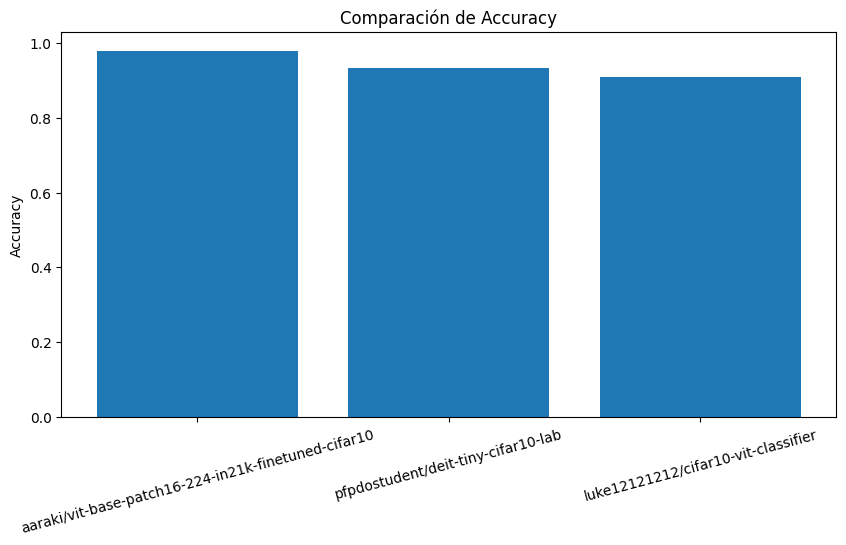

In [22]:
#Visualizaciones
import matplotlib.pyplot as plt

# Accuracy
plt.figure(figsize=(10, 5))

plt.bar(
    results["Model"],
    results["Accuracy"]
)

plt.title("Comparación de Accuracy")
plt.ylabel("Accuracy")
plt.xticks(rotation=15)
plt.show()

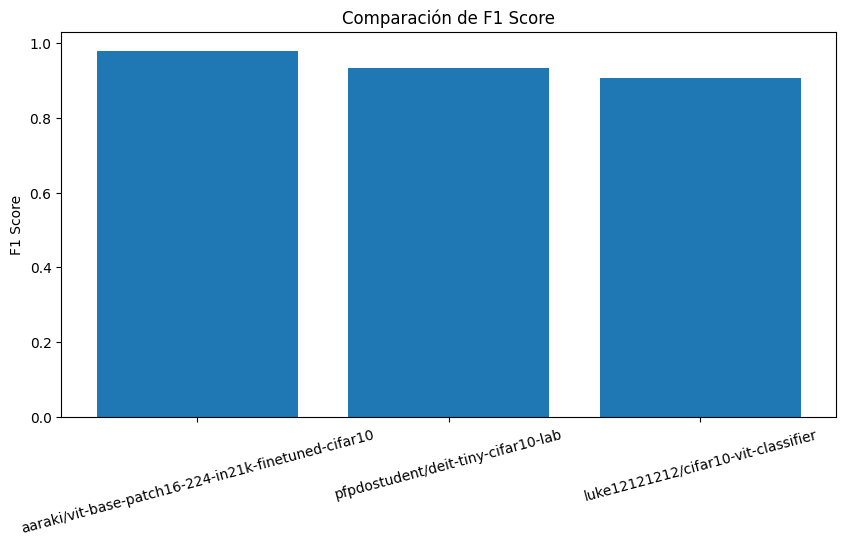

In [25]:
# F1 Score
plt.figure(figsize=(10, 5))

plt.bar(
    results["Model"],
    results["F1"]
)

plt.title("Comparación de F1 Score")
plt.ylabel("F1 Score")
plt.xticks(rotation=15)
plt.show()

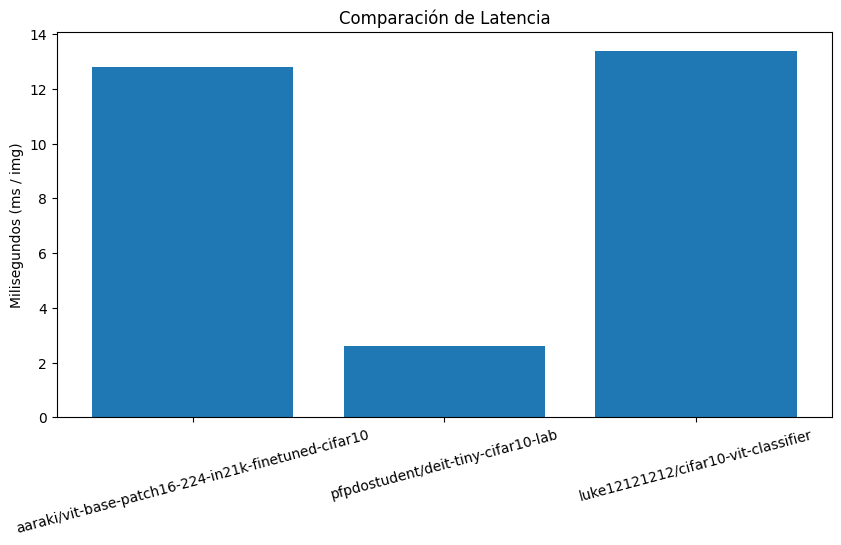

In [27]:
# Latencia (Convertida a milisegundos)
plt.figure(figsize=(10, 5))

# Multiplicamos la columna Latency (s/img) por 1000 para obtener milisegundos
latencia_ms = results["Latency (s/img)"] * 1000

plt.bar(
    results["Model"],
    latencia_ms
)

plt.title("Comparación de Latencia")
plt.ylabel("Milisegundos (ms / img)")
plt.xticks(rotation=15)
plt.show()

# Conclusiones Parciales

**Modelo 1**
*   Mejor precisión
*   Excelente F1-Score
*   Excelente equilibrio precisión-rendimiento


**Modelo 2**
*   Muy rápido
*   Menor latencia
   

**Modelo 3**
*   Generaliza bien
*   Menor desempeño en CIFAR10
*   Mayor consumo computacional
